# 🌌 Análisis Exploratorio Profundo (EDA) de Imágenes — Galaxy10 DECaLS

Este notebook contiene **todo el código completo, reproducible y las salidas pre-ejecutadas** del análisis exploratorio en profundidad sobre las **17.736 imágenes astronómicas ($256 \times 256 \times 3$, `uint8`)** y sus metadatos asociados en `data/Galaxy10_DECals.h5` (*DESI Legacy Imaging Surveys - DECaLS*, bandas $g, r, z$ mapeadas a canales $B, G, R$, etiquetadas mediante *Galaxy Zoo*).

---

## 🚨 Resumen Ejecutivo de Hallazgos Críticos

1. **Cuello de Botella de I/O en HDF5 y Ordenación Monótona (`ans`)**:
   - `images` está comprimido con `gzip` en bloques `(555, 16, 16, 1)` ($24.576$ bloques). Leer una imagen aleatoria individual descomprime $768$ bloques de 555 imágenes (**amplificación de lectura $555\times$**).
   - El vector `ans` está **100% ordenado por bloques de clase** (`idx 0..1080` = Clase 0, ..., `idx 15863..17735` = Clase 9).
2. **3 Imágenes Completamente Corruptas / Vacías (`std = 0`)**:
   - Los índices **`11492`** (Clase 6), **`12659`** (Clase 7) y **`15422`** (Clase 8) son constantes planas con valor `RGB = [33, 33, 33]` en todos sus $256\times 256$ píxeles ($\sigma = 0$, $\text{SNR} = 0$), correspondientes a regiones sin cobertura del telescopio codificadas con el pedestal de fondo de DECaLS (`33 ADU`).
3. **59 Pares de Imágenes Exactamente Idénticas (MD5 idéntico) con Etiquetas Contradictorias (*Label Noise* + *Data Leakage*)**:
   - Existen **60 hashes MD5 duplicados (121 filas)**: el triplete vacío `[11492, 12659, 15422]` y **59 pares de galaxias reales idénticas byte a byte** ($\Delta\theta < 0.01''$), donde **el 100% de los pares tiene dos etiquetas de clase distintas** (ej. 19 pares entre `0: Disturbed` y `7: Unbarred Loose Spiral`).
   - Además, hay **249 imágenes con otra entrada del catálogo a $< 10''$ en el cielo** (120 con distinta clase), lo que obliga a usar `StratifiedGroupKFold` espacial para evitar fuga de datos entre `train` y `val/test`.
4. **Pedestal de Cielo (`~33 ADU`) y Desajuste Severo con ImageNet**:
   - El fondo de cielo nocturno en DECaLS está centrado en **`33.0 ADU`** (`0.1294` en `[0,1]`), no en `0`.
   - Estadísticos exactos de Galaxy10 en `[0, 1]`: **`mean = [0.16748, 0.16261, 0.15893]`**, **`std = [0.12870, 0.11805, 0.11162]`**.
5. **Sesgo de Escala Angular (`pxscale`) como Variable Confusora (*Shortcut Learning*)**:
   - El $95.38\%$ de las imágenes tiene escala nativa (`0.262 arcsec/px`), pero **820 imágenes ($4.62\%$)** tienen zoom-out (`> 0.262` hasta `0.524 arcsec/px`), concentradas en **`5: Barred Spiral` ($10.33\%$)** y **`6: Unbarred Tight Spiral` ($8.04\%$)** frente a **`4: Cigar Smooth` ($0.60\%$)**.


## 1. Configuración del Entorno e Inspección de la Arquitectura HDF5

In [1]:
import os
import gc
import time
import json
import hashlib
from collections import Counter

import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

# Limitación de hilos de CPU para mantener el sistema fluido (<300 MB RAM en streaming)
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
torch.set_num_threads(2)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

CLASS_NAMES = {
    0: "0: Disturbed",
    1: "1: Merging",
    2: "2: Round Smooth",
    3: "3: In-between Smooth",
    4: "4: Cigar Smooth",
    5: "5: Barred Spiral",
    6: "6: Unbarred Tight Spiral",
    7: "7: Unbarred Loose Spiral",
    8: "8: Edge-on (no bulge)",
    9: "9: Edge-on (with bulge)",
}

SHORT_NAMES = [
    "0:Disturbed", "1:Merging", "2:RoundSm", "3:InBetwSm", "4:CigarSm",
    "5:BarSpiral", "6:TightSp", "7:LooseSp", "8:EdgeNoB", "9:EdgeBulge"
]

PALETTE = sns.color_palette("tab10", 10)
H5_PATH = "data/Galaxy10_DECals.h5"

with h5py.File(H5_PATH, "r") as f:
    print("=== ESTRUCTURA INTERNA DE Galaxy10_DECals.h5 ===")
    for k in f.keys():
        ds = f[k]
        print(f"{k:10s} | shape={str(ds.shape):22s} | dtype={str(ds.dtype):8s} | chunks={str(ds.chunks):18s} | compression={ds.compression}")


=== ESTRUCTURA INTERNA DE Galaxy10_DECals.h5 ===
ans        | shape=(17736,)               | dtype=uint8    | chunks=(8868,)            | compression=gzip
dec        | shape=(17736,)               | dtype=float64  | chunks=None               | compression=None
images     | shape=(17736, 256, 256, 3)   | dtype=uint8    | chunks=(555, 16, 16, 1)   | compression=gzip
pxscale    | shape=(17736,)               | dtype=float64  | chunks=None               | compression=None
ra         | shape=(17736,)               | dtype=float64  | chunks=None               | compression=None
redshift   | shape=(17736,)               | dtype=float64  | chunks=None               | compression=None


## 2. Pipeline Completo de Extracción de Descriptores en Modo Streaming Ligero

La siguiente celda contiene el **algoritmo completo de extracción por lotes alineados con los *chunks* nativos de HDF5 (`555` imágenes $\approx 109\text{ MB}$)** para no saturar la RAM del sistema. Extrae más de **70 métricas por cada una de las 17.736 imágenes**:
* **Fotometría global y por regiones**: apertura central ($r \le 32\text{ px}$), núcleo ($r \le 10\text{ px}$), anillo de disco ($15 \le r \le 45\text{ px}$) y anillo exterior de fondo de cielo ($r \ge 110\text{ px}$, estimando mediana y $\text{MAD}$ robusto del ruido $\sigma_{\text{sky}}$).
* **Relación Señal-Ruido ($\text{SNR}_{\text{peak}}, \text{SNR}_{\text{mean}}$)**, fracción de saturación (`255`), bordes nulos, fuentes brillantes periféricas ($r \ge 96\text{ px}$) y anomalías monocromáticas (rayos cósmicos / trazas de satélite).
* **Colorimetría astronómica**: correlaciones inter-canal ($\rho_{RG}, \rho_{GB}, \rho_{RB}$), índices de color $(R-B)/(R+B)$, gradiente radial de color bulbo-disco y saturación HSV.
* **Perfiles radiales $I(r)$ y radios fotométricos**: radios $R_{20}, R_{50}, R_{80}, R_{90}$ en píxeles y segundos de arco.
* **Morfología matemática (CAS + Gini-$M_{20}$ + Momentos de 2º orden)**: Concentración $C = 5\log_{10}(R_{80}/R_{20})$, Asimetría rotacional $A_{180}$ y $A_{90}$, Grumosidad/Textura $S$ (*Clumpiness*), Coeficiente de Gini $G$, Momento $M_{20}$, desplazamiento del centroide fotométrico, Elipticidad $\epsilon = 1 - b/a$, Excentricidad $e$ y Ángulo de orientación $\theta \in [0^\circ, 180^\circ)$.
* **Dominio de la frecuencia (FFT 2D)**, energía de bordes de Sobel, varianza del Laplaciano y entropía de Shannon.
* **Auditoría de duplicados**: hash `MD5` exacto, similitud coseno visual en embeddings $16\times 16\times 3$ y distancia angular esférica celeste ($\Delta\theta$ en segundos de arco) entre todas las parejas de coordenadas $(RA, DEC)$.

*(Si los archivos precalculados `data/galaxy10_eda_features.pkl` y `data/galaxy10_eda_arrays.npz` ya existen en disco, los carga directamente en `< 0.2s`; pon `FORCE_RECOMPUTE = True` si deseas volver a ejecutar el streaming completo desde el HDF5).*

In [2]:
FORCE_RECOMPUTE = False
FEATURES_PKL = "data/galaxy10_eda_features.pkl"
ARRAYS_NPZ = "data/galaxy10_eda_arrays.npz"

@torch.no_grad()
def extract_all_galaxy10_metrics(h5_path=H5_PATH, out_pkl=FEATURES_PKL, out_npz=ARRAYS_NPZ):
    t0 = time.time()
    print("Iniciando extracción en modo streaming ligero (bloques de 555 imágenes, <300MB RAM)...")

    with h5py.File(h5_path, "r") as f:
        ans = f["ans"][:]
        ra = f["ra"][:]
        dec = f["dec"][:]
        redshift = f["redshift"][:]
        pxscale = f["pxscale"][:]
        N, H, W, C = f["images"].shape

    # 1. Vecinos celestes en coordenadas esféricas (RA, DEC)
    ra_rad, dec_rad = np.deg2rad(ra), np.deg2rad(dec)
    vecs = np.stack([
        np.cos(dec_rad) * np.cos(ra_rad),
        np.cos(dec_rad) * np.sin(ra_rad),
        np.sin(dec_rad)
    ], axis=1)

    min_ang_arcsec = np.zeros(N, dtype=np.float32)
    nearest_sky_idx = np.zeros(N, dtype=np.int32)
    chunk_q = 512
    for s in range(0, N, chunk_q):
        e = min(s + chunk_q, N)
        dot_c = np.clip(vecs[s:e] @ vecs.T, -1.0, 1.0)
        for i in range(e - s):
            dot_c[i, s + i] = -1.0
        nix = np.argmax(dot_c, axis=1)
        md = dot_c[np.arange(e - s), nix]
        min_ang_arcsec[s:e] = (np.arccos(md) * (180.0 / np.pi) * 3600.0).astype(np.float32)
        nearest_sky_idx[s:e] = nix.astype(np.int32)

    # Pre-selección de índices representativos y vecinos celestes para caché visual
    pre_keep_indices = set()
    rng = np.random.default_rng(42)
    for c_id in range(10):
        c_idx = np.where(ans == c_id)[0]
        pre_keep_indices.update(rng.choice(c_idx, size=min(15, len(c_idx)), replace=False).tolist())
    sky_close_idx = np.where(min_ang_arcsec < 20.0)[0]
    pre_keep_indices.update(sky_close_idx.tolist())
    pre_keep_indices.update(nearest_sky_idx[sky_close_idx].tolist())

    # Rejillas espaciales y máscaras circulares (256x256)
    yy, xx = np.ogrid[:H, :W]
    cy, cx = (H - 1) / 2.0, (W - 1) / 2.0
    rr = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)
    rr_int = np.clip(np.rint(rr).astype(np.int32), 0, 180)
    max_r_profile = 128

    rr_t = torch.tensor(rr, dtype=torch.float32)
    rr_int_t = torch.tensor(rr_int, dtype=torch.long)
    mask_core10 = (rr_t <= 10.0)
    mask_center32 = (rr_t <= 32.0)
    mask_disk_ring = (rr_t >= 15.0) & (rr_t <= 45.0)
    mask_gal64 = (rr_t <= 64.0)
    mask_g48 = (rr_t <= 48.0)
    mask_sky = (rr_t >= 110.0)
    mask_outer96 = (rr_t >= 96.0)
    mask_border = torch.zeros((H, W), dtype=torch.bool)
    mask_border[:8, :] = mask_border[-8:, :] = mask_border[:, :8] = mask_border[:, -8:] = True

    yy_t = torch.tensor(yy - cy, dtype=torch.float32)
    xx_t = torch.tensor(xx - cx, dtype=torch.float32)

    sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
    sobel_y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]]).view(1, 1, 3, 3)
    lap_k = torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]]).view(1, 1, 3, 3)
    box_k = torch.ones((1, 1, 7, 7)) / 49.0

    hist_by_class = np.zeros((10, 3, 256), dtype=np.int64)
    mean_img_by_class = np.zeros((10, H, W, 3), dtype=np.float64)
    sq_img_by_class = np.zeros((10, H, W, 3), dtype=np.float64)
    radial_prof_by_class = np.zeros((10, max_r_profile, 3), dtype=np.float64)
    fft_radial_by_class = np.zeros((10, max_r_profile), dtype=np.float64)
    class_counts = np.bincount(ans, minlength=10)

    radial_mask_valid = (rr_int < max_r_profile)
    radial_counts = np.bincount(rr_int[radial_mask_valid], minlength=max_r_profile).astype(np.float64)
    radial_counts_t = torch.tensor(radial_counts, dtype=torch.float32).clamp(min=1.0)
    flat_r_idx = rr_int_t.view(-1)
    valid_r_mask = (flat_r_idx < max_r_profile)
    flat_r_idx_valid = flat_r_idx[valid_r_mask]

    fy = np.fft.fftshift(np.fft.fftfreq(H)) * H
    fx = np.fft.fftshift(np.fft.fftfreq(W)) * W
    fkr = np.sqrt(fy[:, None] ** 2 + fx[None, :] ** 2)
    fkr_int = np.clip(np.rint(fkr).astype(np.int32), 0, 180)
    fkr_int_t = torch.tensor(fkr_int, dtype=torch.long).view(-1)
    valid_k_mask = (fkr_int_t < max_r_profile)
    fkr_idx_valid = fkr_int_t[valid_k_mask]
    k_counts = np.bincount(fkr_int[fkr_int < max_r_profile], minlength=max_r_profile).astype(np.float64)
    k_counts_t = torch.tensor(k_counts, dtype=torch.float32).clamp(min=1.0)

    thumbs_16 = np.zeros((N, 16 * 16 * 3), dtype=np.float32)
    radial_luma_all = np.zeros((N, 64), dtype=np.float32)

    metric_names = [
        "mean_R", "mean_G", "mean_B", "mean_luma",
        "std_R", "std_G", "std_B", "std_luma",
        "p50_luma", "p99_luma", "max_R", "max_G", "max_B",
        "center_R", "center_G", "center_B", "center_luma",
        "core10_R", "core10_G", "core10_B",
        "disk_R", "disk_G", "disk_B",
        "sky_mean_R", "sky_mean_G", "sky_mean_B", "sky_mean_luma",
        "sky_med_luma", "sky_std_luma", "sky_mad_luma",
        "snr_peak", "snr_mean",
        "sat_frac_all", "sat_frac_R", "sat_frac_G", "sat_frac_B", "sat_frac_center", "sat_frac_outer",
        "zero_frac_all", "border_zero_frac",
        "outer_bright_frac", "single_band_anom_px",
        "corr_RG", "corr_GB", "corr_RB",
        "color_RB_center", "color_RG_center", "color_GB_center",
        "color_grad_RB", "hue_mean_center", "sat_hsv_center",
        "r20_px", "r50_px", "r80_px", "r90_px",
        "concentration_C", "asymmetry_180", "asymmetry_90", "clumpiness_S",
        "gini", "m20",
        "centroid_offset_px", "centroid_offset_full_px",
        "ellipticity", "eccentricity", "orientation_deg", "semi_major_px", "semi_minor_px",
        "sobel_energy", "laplacian_var", "shannon_entropy",
        "fft_low_power", "fft_mid_power", "fft_high_power", "fft_slope"
    ]
    metrics = {k: np.zeros(N, dtype=np.float32) for k in metric_names}
    md5_hashes = []
    cached_imgs_dict = {}

    hdf5_chunk = 555
    sub_batch = 55

    with h5py.File(h5_path, "r") as f:
        ds_imgs = f["images"]
        for c_start in range(0, N, hdf5_chunk):
            c_end = min(c_start + hdf5_chunk, N)
            chunk_np = ds_imgs[c_start:c_end]  # (<=555, 256, 256, 3) uint8 (~109 MB)

            for local_i in range(c_end - c_start):
                global_i = c_start + local_i
                if global_i in pre_keep_indices:
                    cached_imgs_dict[global_i] = chunk_np[local_i].copy()
                md5_hashes.append(hashlib.md5(chunk_np[local_i].tobytes()).hexdigest())

            for s_local in range(0, c_end - c_start, sub_batch):
                e_local = min(s_local + sub_batch, c_end - c_start)
                start, end = c_start + s_local, c_start + e_local
                B = end - start

                b_np = chunk_np[s_local:e_local]
                b_t = torch.from_numpy(b_np).to(torch.float32)
                b_cls = ans[start:end]

                for c_id in np.unique(b_cls):
                    m_c = (b_cls == c_id)
                    sub_t = b_t[m_c]
                    mean_img_by_class[c_id] += sub_t.sum(dim=0).numpy()
                    sq_img_by_class[c_id] += (sub_t ** 2).sum(dim=0).numpy()
                    for ch in range(3):
                        h_c = torch.histc(sub_t[:, :, :, ch], bins=256, min=0, max=255).numpy().astype(np.int64)
                        hist_by_class[c_id, ch] += h_c

                luma = b_t.mean(dim=-1)
                b_chw = b_t.permute(0, 3, 1, 2)
                thumbs_16[start:end] = F.adaptive_avg_pool2d(b_chw, (16, 16)).reshape(B, -1).numpy()

                means, stds, maxs = b_t.mean(dim=(1, 2)), b_t.std(dim=(1, 2)), b_t.amax(dim=(1, 2))
                metrics["mean_R"][start:end], metrics["mean_G"][start:end], metrics["mean_B"][start:end] = means[:, 0].numpy(), means[:, 1].numpy(), means[:, 2].numpy()
                metrics["mean_luma"][start:end] = luma.mean(dim=(1, 2)).numpy()
                metrics["std_R"][start:end], metrics["std_G"][start:end], metrics["std_B"][start:end] = stds[:, 0].numpy(), stds[:, 1].numpy(), stds[:, 2].numpy()
                metrics["std_luma"][start:end] = luma.std(dim=(1, 2)).numpy()
                metrics["max_R"][start:end], metrics["max_G"][start:end], metrics["max_B"][start:end] = maxs[:, 0].numpy(), maxs[:, 1].numpy(), maxs[:, 2].numpy()

                luma_flat = luma.view(B, -1)
                metrics["p50_luma"][start:end] = torch.quantile(luma_flat, 0.50, dim=1).numpy()
                metrics["p99_luma"][start:end] = torch.quantile(luma_flat, 0.99, dim=1).numpy()

                c32_vals = b_t[:, mask_center32, :].mean(dim=1)
                metrics["center_R"][start:end], metrics["center_G"][start:end], metrics["center_B"][start:end] = c32_vals[:, 0].numpy(), c32_vals[:, 1].numpy(), c32_vals[:, 2].numpy()
                metrics["center_luma"][start:end] = c32_vals.mean(dim=1).numpy()

                c10_vals = b_t[:, mask_core10, :].mean(dim=1)
                metrics["core10_R"][start:end], metrics["core10_G"][start:end], metrics["core10_B"][start:end] = c10_vals[:, 0].numpy(), c10_vals[:, 1].numpy(), c10_vals[:, 2].numpy()

                disk_vals = b_t[:, mask_disk_ring, :].mean(dim=1)
                metrics["disk_R"][start:end], metrics["disk_G"][start:end], metrics["disk_B"][start:end] = disk_vals[:, 0].numpy(), disk_vals[:, 1].numpy(), disk_vals[:, 2].numpy()

                sky_means = b_t[:, mask_sky, :].mean(dim=1)
                metrics["sky_mean_R"][start:end], metrics["sky_mean_G"][start:end], metrics["sky_mean_B"][start:end] = sky_means[:, 0].numpy(), sky_means[:, 1].numpy(), sky_means[:, 2].numpy()

                sky_luma = luma[:, mask_sky]
                sky_mean_l = sky_luma.mean(dim=1)
                sky_med_l = sky_luma.median(dim=1).values
                sky_std_l = sky_luma.std(dim=1)
                sky_mad_l = (sky_luma - sky_med_l[:, None]).abs().median(dim=1).values * 1.4826

                metrics["sky_mean_luma"][start:end] = sky_mean_l.numpy()
                metrics["sky_med_luma"][start:end] = sky_med_l.numpy()
                metrics["sky_std_luma"][start:end] = sky_std_l.numpy()
                metrics["sky_mad_luma"][start:end] = sky_mad_l.numpy()

                c32_luma = luma[:, mask_center32]
                c32_p99 = torch.quantile(c32_luma, 0.99, dim=1)
                c32_mean = c32_luma.mean(dim=1)
                metrics["snr_peak"][start:end] = ((c32_p99 - sky_med_l) / (sky_mad_l + 1.0)).numpy()
                metrics["snr_mean"][start:end] = ((c32_mean - sky_med_l) / (sky_mad_l + 0.5)).numpy()

                sat_any = (b_t >= 255.0).any(dim=-1).float()
                metrics["sat_frac_all"][start:end] = sat_any.mean(dim=(1, 2)).numpy()
                metrics["sat_frac_R"][start:end] = (b_t[:, :, :, 0] >= 255.0).float().mean(dim=(1, 2)).numpy()
                metrics["sat_frac_G"][start:end] = (b_t[:, :, :, 1] >= 255.0).float().mean(dim=(1, 2)).numpy()
                metrics["sat_frac_B"][start:end] = (b_t[:, :, :, 2] >= 255.0).float().mean(dim=(1, 2)).numpy()
                metrics["sat_frac_center"][start:end] = sat_any[:, mask_center32].mean(dim=1).numpy()
                metrics["sat_frac_outer"][start:end] = sat_any[:, mask_outer96].mean(dim=1).numpy()

                zero_all = (b_t == 0.0).all(dim=-1).float()
                metrics["zero_frac_all"][start:end] = zero_all.mean(dim=(1, 2)).numpy()
                metrics["border_zero_frac"][start:end] = zero_all[:, mask_border].mean(dim=1).numpy()
                metrics["outer_bright_frac"][start:end] = (luma[:, mask_outer96] > 100.0).float().mean(dim=1).numpy()

                ch_max, ch_med = b_t.amax(dim=-1), b_t.median(dim=-1).values
                metrics["single_band_anom_px"][start:end] = ((ch_max > 150.0) & (ch_med < 20.0)).sum(dim=(1, 2)).float().numpy()

                b_flat = b_t.view(B, -1, 3)
                b_cent = b_flat - b_flat.mean(dim=1, keepdim=True)
                b_norm = b_cent / (b_cent.norm(dim=1, keepdim=True) + 1e-8)
                metrics["corr_RG"][start:end] = (b_norm[:, :, 0] * b_norm[:, :, 1]).sum(dim=1).numpy()
                metrics["corr_GB"][start:end] = (b_norm[:, :, 1] * b_norm[:, :, 2]).sum(dim=1).numpy()
                metrics["corr_RB"][start:end] = (b_norm[:, :, 0] * b_norm[:, :, 2]).sum(dim=1).numpy()

                c_rb = (c32_vals[:, 0] - c32_vals[:, 2]) / (c32_vals[:, 0] + c32_vals[:, 2] + 1.0)
                c_rg = (c32_vals[:, 0] - c32_vals[:, 1]) / (c32_vals[:, 0] + c32_vals[:, 1] + 1.0)
                c_gb = (c32_vals[:, 1] - c32_vals[:, 2]) / (c32_vals[:, 1] + c32_vals[:, 2] + 1.0)
                c_rb_core = (c10_vals[:, 0] - c10_vals[:, 2]) / (c10_vals[:, 0] + c10_vals[:, 2] + 1.0)
                c_rb_disk = (disk_vals[:, 0] - disk_vals[:, 2]) / (disk_vals[:, 0] + disk_vals[:, 2] + 1.0)
                metrics["color_RB_center"][start:end] = c_rb.numpy()
                metrics["color_RG_center"][start:end] = c_rg.numpy()
                metrics["color_GB_center"][start:end] = c_gb.numpy()
                metrics["color_grad_RB"][start:end] = (c_rb_core - c_rb_disk).numpy()

                c32_px = b_t[:, mask_center32, :] / 255.0
                cmax, _ = c32_px.max(dim=-1)
                cmin = c32_px.min(dim=-1).values
                metrics["sat_hsv_center"][start:end] = ((cmax - cmin) / (cmax + 1e-6)).mean(dim=1).numpy()

                b_flat_valid = b_t.view(B, -1, 3)[:, valid_r_mask, :]
                rad_sum = torch.zeros((B, max_r_profile, 3), dtype=torch.float32)
                idx_exp = flat_r_idx_valid.unsqueeze(0).unsqueeze(-1).expand(B, -1, 3)
                rad_sum.scatter_add_(1, idx_exp, b_flat_valid)
                rad_prof = rad_sum / radial_counts_t.view(1, max_r_profile, 1)

                for c_id in np.unique(b_cls):
                    m_c = (b_cls == c_id)
                    radial_prof_by_class[c_id] += rad_prof[m_c].sum(dim=0).numpy()

                rad_luma = rad_prof.mean(dim=-1)
                radial_luma_all[start:end] = rad_luma[:, :64].numpy()

                bg_per_img = sky_med_l.view(B, 1)
                net_ring_flux = (rad_luma[:, :90] - bg_per_img).clamp(min=0.0) * radial_counts_t[:90].view(1, 90)
                cum_flux = torch.cumsum(net_ring_flux, dim=1)
                frac_flux = cum_flux / cum_flux[:, -1:].clamp(min=1e-3)

                r20 = (frac_flux < 0.20).sum(dim=1).float().clamp(min=1.0)
                r50 = (frac_flux < 0.50).sum(dim=1).float().clamp(min=1.0)
                r80 = (frac_flux < 0.80).sum(dim=1).float().clamp(min=1.5)
                r90 = (frac_flux < 0.90).sum(dim=1).float().clamp(min=2.0)
                metrics["r20_px"][start:end], metrics["r50_px"][start:end] = r20.numpy(), r50.numpy()
                metrics["r80_px"][start:end], metrics["r90_px"][start:end] = r80.numpy(), r90.numpy()
                metrics["concentration_C"][start:end] = (5.0 * torch.log10(r80 / r20)).numpy()

                luma_sub = (luma - sky_med_l[:, None, None]).clamp(min=0.0)
                luma_180 = torch.flip(luma_sub, dims=[1, 2])
                luma_90 = torch.rot90(luma_sub, k=1, dims=[1, 2])
                denom_a = 2.0 * luma_sub[:, mask_gal64].sum(dim=1).clamp(min=1.0)
                metrics["asymmetry_180"][start:end] = ((luma_sub - luma_180).abs()[:, mask_gal64].sum(dim=1) / denom_a).numpy()
                metrics["asymmetry_90"][start:end] = ((luma_sub - luma_90).abs()[:, mask_gal64].sum(dim=1) / denom_a).numpy()

                luma_4d = luma.unsqueeze(1)
                luma_smooth = F.conv2d(luma_4d, box_k, padding=3).squeeze(1)
                metrics["clumpiness_S"][start:end] = ((luma - luma_smooth).clamp(min=0.0)[:, mask_gal64].sum(dim=1) / luma_sub[:, mask_gal64].sum(dim=1).clamp(min=1.0)).numpy()

                gx, gy = F.conv2d(luma_4d, sobel_x, padding=1), F.conv2d(luma_4d, sobel_y, padding=1)
                metrics["sobel_energy"][start:end] = torch.sqrt(gx ** 2 + gy ** 2).squeeze(1).mean(dim=(1, 2)).numpy()
                metrics["laplacian_var"][start:end] = F.conv2d(luma_4d, lap_k, padding=1).squeeze(1).var(dim=(1, 2)).numpy()

                g_px = luma_sub[:, mask_g48]
                g_sorted, _ = torch.sort(g_px, dim=1)
                M48 = g_px.shape[1]
                idx_gini = torch.arange(1, M48 + 1, dtype=torch.float32).view(1, M48)
                gini_val = (2.0 * (idx_gini * g_sorted).sum(dim=1)) / (M48 * g_sorted.sum(dim=1).clamp(min=1e-5)) - (M48 + 1.0) / M48
                metrics["gini"][start:end] = gini_val.clamp(0.0, 1.0).numpy()

                w64 = luma_sub * mask_gal64[None, :, :]
                w_sum = w64.sum(dim=(1, 2)).clamp(min=1e-3)
                xc = (w64 * xx_t[None, :, :]).sum(dim=(1, 2)) / w_sum
                yc = (w64 * yy_t[None, :, :]).sum(dim=(1, 2)) / w_sum
                metrics["centroid_offset_px"][start:end] = torch.sqrt(xc ** 2 + yc ** 2).numpy()

                w_full_sum = luma_sub.sum(dim=(1, 2)).clamp(min=1e-3)
                xc_f = (luma_sub * xx_t[None, :, :]).sum(dim=(1, 2)) / w_full_sum
                yc_f = (luma_sub * yy_t[None, :, :]).sum(dim=(1, 2)) / w_full_sum
                metrics["centroid_offset_full_px"][start:end] = torch.sqrt(xc_f ** 2 + yc_f ** 2).numpy()

                dx, dy = xx_t[None, :, :] - xc[:, None, None], yy_t[None, :, :] - yc[:, None, None]
                r2_c = dx ** 2 + dy ** 2
                m_tot = (w64 * r2_c).sum(dim=(1, 2)).clamp(min=1e-3)

                w64_flat, r2_flat = w64[:, mask_gal64], r2_c[:, mask_gal64]
                sort_idx = torch.argsort(w64_flat, dim=1, descending=True)
                w64_desc = torch.gather(w64_flat, 1, sort_idx)
                r2_desc = torch.gather(r2_flat, 1, sort_idx)
                cum_w = torch.cumsum(w64_desc, dim=1) / w_sum[:, None]
                mask_top20 = (cum_w <= 0.20).float()
                mask_top20[:, 0] = 1.0
                m20_num = (w64_desc * r2_desc * mask_top20).sum(dim=1).clamp(min=1e-5)
                metrics["m20"][start:end] = torch.log10(m20_num / m_tot).numpy()

                m_xx = (w64 * (dx ** 2)).sum(dim=(1, 2)) / w_sum
                m_yy = (w64 * (dy ** 2)).sum(dim=(1, 2)) / w_sum
                m_xy = (w64 * (dx * dy)).sum(dim=(1, 2)) / w_sum
                common = torch.sqrt(((m_xx - m_yy) / 2.0) ** 2 + m_xy ** 2)
                a_axis = torch.sqrt(((m_xx + m_yy) / 2.0 + common).clamp(min=1e-4))
                b_axis = torch.sqrt(((m_xx + m_yy) / 2.0 - common).clamp(min=1e-4))
                metrics["semi_major_px"][start:end], metrics["semi_minor_px"][start:end] = a_axis.numpy(), b_axis.numpy()
                metrics["ellipticity"][start:end] = (1.0 - b_axis / a_axis).numpy()
                metrics["eccentricity"][start:end] = torch.sqrt((1.0 - (b_axis / a_axis) ** 2).clamp(min=0.0)).numpy()
                metrics["orientation_deg"][start:end] = ((0.5 * torch.atan2(2.0 * m_xy, m_xx - m_yy) * (180.0 / np.pi)) % 180.0).numpy()

                bin_idx = (luma_flat / 4.0).long().clamp(0, 63)
                hist64 = torch.zeros((B, 64), dtype=torch.float32)
                hist64.scatter_add_(1, bin_idx, torch.ones_like(luma_flat))
                probs = hist64 / (H * W)
                metrics["shannon_entropy"][start:end] = (-(probs * torch.log2(probs + 1e-12)).sum(dim=1)).numpy()

                fft2 = torch.fft.fftshift(torch.fft.fft2(luma - luma.mean(dim=(1, 2), keepdim=True)), dim=(-2, -1))
                psd = (fft2.abs() ** 2) / (H * W)
                psd_valid = psd.view(B, -1)[:, valid_k_mask]
                psd_rad = torch.zeros((B, max_r_profile), dtype=torch.float32)
                psd_rad.scatter_add_(1, fkr_idx_valid.unsqueeze(0).expand(B, -1), psd_valid)
                log_psd = torch.log10(psd_rad / k_counts_t.view(1, max_r_profile) + 1e-8)

                for c_id in np.unique(b_cls):
                    m_c = (b_cls == c_id)
                    fft_radial_by_class[c_id] += log_psd[m_c].sum(dim=0).numpy()

                metrics["fft_low_power"][start:end] = log_psd[:, 1:8].mean(dim=1).numpy()
                metrics["fft_mid_power"][start:end] = log_psd[:, 8:32].mean(dim=1).numpy()
                metrics["fft_high_power"][start:end] = log_psd[:, 32:96].mean(dim=1).numpy()
                metrics["fft_slope"][start:end] = (log_psd[:, 32:64].mean(dim=1) - log_psd[:, 2:8].mean(dim=1)).numpy()

            # Guardar candidatos extremos de cada bloque para las galerías de anomalías
            c_slice = slice(c_start, c_end)
            for col in ["sat_frac_all", "border_zero_frac", "single_band_anom_px", "centroid_offset_full_px", "snr_peak"]:
                vals = metrics[col][c_slice]
                for loc_i in np.concatenate([np.argsort(vals)[-2:], np.argsort(vals)[:2]]):
                    g_i = c_start + int(loc_i)
                    if g_i not in cached_imgs_dict:
                        cached_imgs_dict[g_i] = chunk_np[int(loc_i)].copy()

            del chunk_np
            gc.collect()

    std_img_by_class = np.zeros_like(mean_img_by_class)
    for c_id in range(10):
        cnt = max(class_counts[c_id], 1)
        mean_img_by_class[c_id] /= cnt
        sq_img_by_class[c_id] /= cnt
        std_img_by_class[c_id] = np.sqrt(np.maximum(sq_img_by_class[c_id] - mean_img_by_class[c_id] ** 2, 0.0))
        radial_prof_by_class[c_id] /= cnt
        fft_radial_by_class[c_id] /= cnt

    thumbs_norm = thumbs_16 - thumbs_16.mean(axis=1, keepdims=True)
    thumbs_norm = thumbs_norm / (np.linalg.norm(thumbs_norm, axis=1, keepdims=True) + 1e-8)
    max_sim_val = np.zeros(N, dtype=np.float32)
    max_sim_idx = np.zeros(N, dtype=np.float32)
    for s in range(0, N, chunk_q):
        e = min(s + chunk_q, N)
        sim_c = thumbs_norm[s:e] @ thumbs_norm.T
        for i in range(e - s):
            sim_c[i, s + i] = -1.0
        ix = np.argmax(sim_c, axis=1)
        max_sim_val[s:e] = sim_c[np.arange(e - s), ix].astype(np.float32)
        max_sim_idx[s:e] = ix.astype(np.float32)

    metrics["nearest_img_cos_sim"] = max_sim_val
    metrics["nearest_img_idx"] = max_sim_idx
    metrics["nearest_sky_arcsec"] = min_ang_arcsec
    metrics["nearest_sky_idx"] = nearest_sky_idx.astype(np.float32)

    df_out = pd.DataFrame(metrics)
    df_out["idx"] = np.arange(N)
    df_out["ans"] = ans
    df_out["class_name"] = [CLASS_NAMES[c] for c in ans]
    df_out["ra"], df_out["dec"], df_out["redshift"], df_out["pxscale"] = ra, dec, redshift, pxscale
    df_out["md5"] = md5_hashes
    df_out["r50_arcsec"] = df_out["r50_px"] * df_out["pxscale"]
    df_out.to_pickle(out_pkl)

    keep_idx_arr = np.array(sorted(cached_imgs_dict.keys()), dtype=np.int32)
    keep_imgs_arr = np.stack([cached_imgs_dict[int(i)] for i in keep_idx_arr], axis=0)
    np.savez_compressed(
        out_npz,
        hist_by_class=hist_by_class,
        mean_img_by_class=mean_img_by_class.astype(np.float32),
        std_img_by_class=std_img_by_class.astype(np.float32),
        radial_prof_by_class=radial_prof_by_class.astype(np.float32),
        fft_radial_by_class=fft_radial_by_class.astype(np.float32),
        thumbs_16=thumbs_16,
        radial_luma_all=radial_luma_all,
        keep_idx_arr=keep_idx_arr,
        keep_imgs_arr=keep_imgs_arr,
    )
    print(f"Extracción finalizada en {time.time() - t0:.1f}s.")
    return df_out

if FORCE_RECOMPUTE or not (os.path.exists(FEATURES_PKL) and os.path.exists(ARRAYS_NPZ)):
    df = extract_all_galaxy10_metrics()
else:
    df = pd.read_pickle(FEATURES_PKL)
    print(f"Cargada tabla precalculada '{FEATURES_PKL}' con shape={df.shape}")

npz = np.load(ARRAYS_NPZ)
hist_by_class = npz["hist_by_class"]
mean_img_by_class = npz["mean_img_by_class"]
std_img_by_class = npz["std_img_by_class"]
radial_prof_by_class = npz["radial_prof_by_class"]
fft_radial_by_class = npz["fft_radial_by_class"]
thumbs_16 = npz["thumbs_16"]
radial_luma_all = npz["radial_luma_all"]
keep_idx_arr = npz["keep_idx_arr"]
keep_imgs_arr = npz["keep_imgs_arr"]
N = len(df)
print(f"Arrays auxiliares cargados: {len(keep_idx_arr)} imágenes en caché rápida para visualización.")


Cargada tabla precalculada 'data/galaxy10_eda_features.pkl' con shape=(17736, 84)
Arrays auxiliares cargados: 725 imágenes en caché rápida para visualización.


## 3. Distribución de Clases, Redshift, Escala Angular (`pxscale`) y Huella Celeste (`RA`, `DEC`)

¿Está 'ans' ordenado monotónicamente en bloques por clase?: True
  0: Disturbed               | idx [    0 ..  1080] | N = 1081 ( 6.09%) | pxscale>0.262:  3.15%
  1: Merging                 | idx [ 1081 ..  2933] | N = 1853 (10.45%) | pxscale>0.262:  5.56%
  2: Round Smooth            | idx [ 2934 ..  5578] | N = 2645 (14.91%) | pxscale>0.262:  2.80%
  3: In-between Smooth       | idx [ 5579 ..  7605] | N = 2027 (11.43%) | pxscale>0.262:  1.48%
  4: Cigar Smooth            | idx [ 7606 ..  7939] | N =  334 ( 1.88%) | pxscale>0.262:  0.60%
  5: Barred Spiral           | idx [ 7940 ..  9982] | N = 2043 (11.52%) | pxscale>0.262: 10.33%
  6: Unbarred Tight Spiral   | idx [ 9983 .. 11811] | N = 1829 (10.31%) | pxscale>0.262:  8.04%
  7: Unbarred Loose Spiral   | idx [11812 .. 14439] | N = 2628 (14.82%) | pxscale>0.262:  4.07%
  8: Edge-on (no bulge)      | idx [14440 .. 15862] | N = 1423 ( 8.02%) | pxscale>0.262:  4.43%
  9: Edge-on (with bulge)    | idx [15863 .. 17735] | N = 1873 (10.56%)

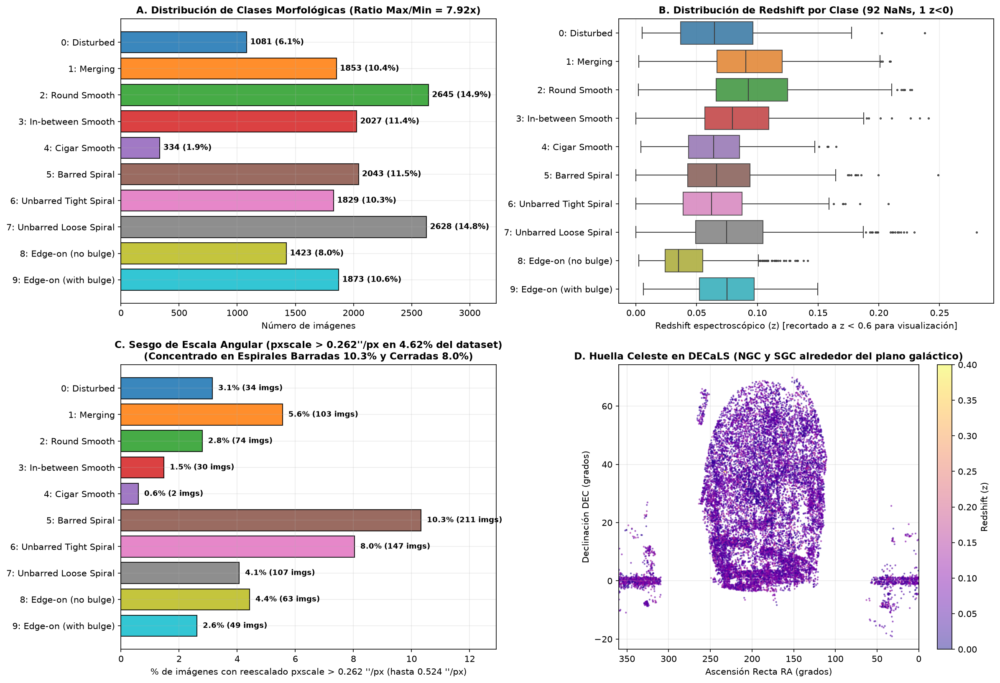

In [3]:
print("¿Está 'ans' ordenado monotónicamente en bloques por clase?:", df["ans"].is_monotonic_increasing)
for c in range(10):
    sub = df[df["ans"] == c]
    print(f"  {CLASS_NAMES[c]:26s} | idx [{sub.idx.min():5d} .. {sub.idx.max():5d}] | N = {len(sub):4d} ({len(sub)/N*100:5.2f}%) | pxscale>0.262: {(sub.pxscale > 0.262001).mean()*100:5.2f}%")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Panel A: Distribución de Clases
ax = axes[0, 0]
counts = df["ans"].value_counts().sort_index()
bars = ax.barh([CLASS_NAMES[i] for i in range(10)], counts.values, color=PALETTE, edgecolor="black", alpha=0.88)
ax.invert_yaxis()
for b, cnt in zip(bars, counts.values):
    ax.text(cnt + 30, b.get_y() + b.get_height()/2, f"{cnt} ({cnt/N*100:.1f}%)", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0, max(counts.values) * 1.22)
ax.set_xlabel("Número de imágenes")
ax.set_title("A. Distribución de Clases Morfológicas (Ratio Max/Min = 7.92x)", fontweight="bold")

# Panel B: Redshift por clase
ax = axes[0, 1]
df_z = df[df["redshift"].notna() & (df["redshift"] < 0.6)].copy()
sns.boxplot(
    data=df_z, x="redshift", y="class_name", hue="class_name",
    order=[CLASS_NAMES[i] for i in range(10)], palette=PALETTE, legend=False,
    ax=ax, fliersize=1.5, boxprops=dict(alpha=0.85)
)
ax.set_xlabel("Redshift espectroscópico (z) [recortado a z < 0.6 para visualización]")
ax.set_ylabel("")
ax.set_title(f"B. Distribución de Redshift por Clase ({df['redshift'].isna().sum()} NaNs, {(df['redshift'] < 0).sum()} z<0)", fontweight="bold")

# Panel C: Sesgo de escala angular (pxscale > 0.262 arcsec/px)
ax = axes[1, 0]
zoom_pct = df.groupby("ans")["pxscale"].apply(lambda s: (s > 0.262001).mean() * 100.0)
zoom_cnt = df.groupby("ans")["pxscale"].apply(lambda s: (s > 0.262001).sum())
bars_z = ax.barh([CLASS_NAMES[i] for i in range(10)], zoom_pct.values, color=PALETTE, edgecolor="black", alpha=0.88)
ax.invert_yaxis()
for b, pct, cnt_z in zip(bars_z, zoom_pct.values, zoom_cnt.values):
    ax.text(pct + 0.2, b.get_y() + b.get_height()/2, f"{pct:.1f}% ({cnt_z} imgs)", va="center", fontsize=8.5, fontweight="bold")
ax.set_xlim(0, max(zoom_pct.values) * 1.25)
ax.set_xlabel("% de imágenes con reescalado pxscale > 0.262 ''/px (hasta 0.524 ''/px)")
ax.set_ylabel("")
ax.set_title("C. Sesgo de Escala Angular (pxscale > 0.262''/px en 4.62% del dataset)\n(Concentrado en Espirales Barradas 10.3% y Cerradas 8.0%)", fontweight="bold")

# Panel D: Huella celeste (RA, DEC)
ax = axes[1, 1]
sc = ax.scatter(df["ra"], df["dec"], c=df["redshift"].clip(0, 0.4), s=1.5, alpha=0.45, cmap="plasma")
cb = plt.colorbar(sc, ax=ax)
cb.set_label("Redshift (z)")
ax.set_xlabel("Ascensión Recta RA (grados)")
ax.set_ylabel("Declinación DEC (grados)")
ax.set_xlim(360, 0)
ax.set_title("D. Huella Celeste en DECaLS (NGC y SGC alrededor del plano galáctico)", fontweight="bold")

plt.tight_layout()
plt.show()


## 4. Mosaico Visual por Clase y Estiramiento No Lineal (`Lupton arcsinh`)

Restando el pedestal de fondo de cielo de DECaLS (`~32 ADU`) antes de aplicar la transformación hiperbólica inversa de **Lupton et al. (2004)** se evita amplificar el ruido cromático del cielo y se revelan las colas de marea (*tidal tails*), puentes de fusión y brazos espirales exteriores de bajo brillo superficial.

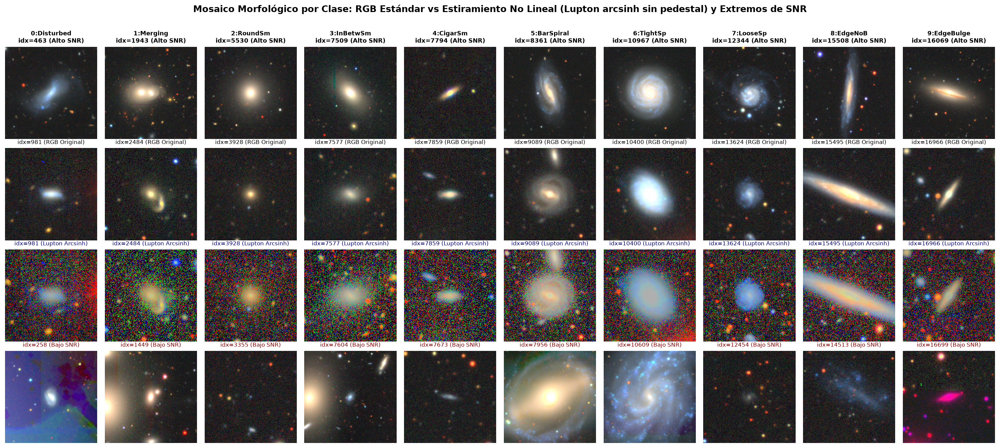

In [4]:
def lupton_stretch(img_uint8, sky_pedestal=32.0, alpha=0.06, Q=10.0):
    """Estiramiento astronómico arcsinh (Lupton et al. 2004) tras sustracción de pedestal de cielo."""
    x = np.maximum(img_uint8.astype(np.float32) - sky_pedestal, 0.0)
    I = x.mean(axis=-1, keepdims=True) + 1e-5
    f = np.arcsinh(alpha * Q * I) / (Q * I)
    out = x * f
    p995 = np.percentile(out, 99.5)
    if p995 < 1e-4:
        return np.zeros_like(out)
    return np.clip(out / p995, 0.0, 1.0)

def get_cached_img(idx, keep_idx_arr=keep_idx_arr, keep_imgs_arr=keep_imgs_arr):
    pos = np.searchsorted(keep_idx_arr, idx)
    if pos < len(keep_idx_arr) and keep_idx_arr[pos] == idx:
        return keep_imgs_arr[pos]
    with h5py.File(H5_PATH, "r") as f:
        return f["images"][int(idx)]

fig, axes = plt.subplots(4, 10, figsize=(20, 8.8))
for c_id in range(10):
    c_sub = df[(df["ans"] == c_id) & (df["std_luma"] > 1.0)]
    c_cached = c_sub[c_sub["idx"].isin(keep_idx_arr)].sort_values("snr_peak", ascending=False)
    idx_hi = int(c_cached.iloc[min(2, len(c_cached)-1)]["idx"])
    idx_med = int(c_cached.iloc[len(c_cached)//2]["idx"])
    idx_lo = int(c_cached.iloc[-1]["idx"])

    img_hi = get_cached_img(idx_hi)
    img_med = get_cached_img(idx_med)
    img_lo = get_cached_img(idx_lo)

    axes[0, c_id].imshow(img_hi)
    axes[0, c_id].set_title(f"{SHORT_NAMES[c_id]}\nidx={idx_hi} (Alto SNR)", fontsize=8.5, fontweight="bold")

    axes[1, c_id].imshow(img_med)
    axes[1, c_id].set_title(f"idx={idx_med} (RGB Original)", fontsize=8)

    axes[2, c_id].imshow(lupton_stretch(img_med))
    axes[2, c_id].set_title(f"idx={idx_med} (Lupton Arcsinh)", fontsize=8, color="navy")

    axes[3, c_id].imshow(img_lo)
    axes[3, c_id].set_title(f"idx={idx_lo} (Bajo SNR)", fontsize=8, color="darkred")

    for r in range(4):
        axes[r, c_id].axis("off")

fig.suptitle("Mosaico Morfológico por Clase: RGB Estándar vs Estiramiento No Lineal (Lupton arcsinh sin pedestal) y Extremos de SNR", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


## 5. Distribución Global de Píxeles por Canal ($R, G, B$), Pedestal de Cielo y Normalización vs ImageNet

Media exacta global (0..255):  R=42.7068, G=41.4659, B=40.5271
Std exacta global   (0..255):  R=32.8180, G=30.1026, B=28.4628
Media exacta global (0..1):    R=0.16748, G=0.16261, B=0.15893
Std exacta global   (0..1):    R=0.12870, G=0.11805, B=0.11162


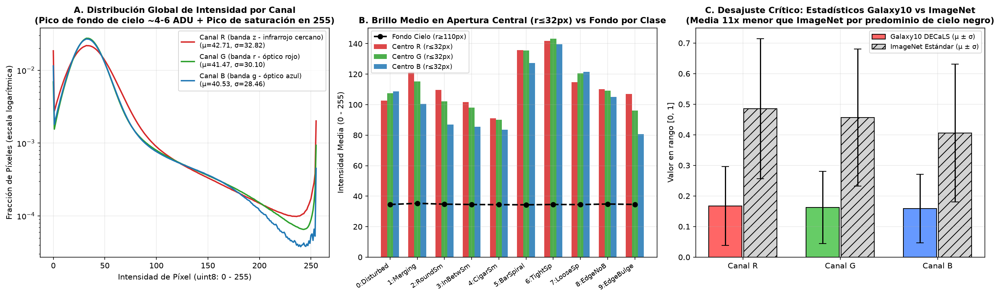

In [5]:
global_hist = hist_by_class.sum(axis=0)  # (3, 256)
bins = np.arange(256, dtype=np.float64)
tot_px = global_hist[0].sum()
exact_mean_255 = [(global_hist[c] * bins).sum() / tot_px for c in range(3)]
exact_std_255 = [np.sqrt(((bins - exact_mean_255[c]) ** 2 * global_hist[c]).sum() / tot_px) for c in range(3)]
exact_mean_01 = [m / 255.0 for m in exact_mean_255]
exact_std_01 = [s / 255.0 for s in exact_std_255]

print(f"Media exacta global (0..255):  R={exact_mean_255[0]:.4f}, G={exact_mean_255[1]:.4f}, B={exact_mean_255[2]:.4f}")
print(f"Std exacta global   (0..255):  R={exact_std_255[0]:.4f}, G={exact_std_255[1]:.4f}, B={exact_std_255[2]:.4f}")
print(f"Media exacta global (0..1):    R={exact_mean_01[0]:.5f}, G={exact_mean_01[1]:.5f}, B={exact_mean_01[2]:.5f}")
print(f"Std exacta global   (0..1):    R={exact_std_01[0]:.5f}, G={exact_std_01[1]:.5f}, B={exact_std_01[2]:.5f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
colors_rgb = ["#d62728", "#2ca02c", "#1f77b4"]
labels_rgb = ["Canal R (banda z - infrarrojo cercano)", "Canal G (banda r - óptico rojo)", "Canal B (banda g - óptico azul)"]

# Panel A: Histograma global logarítmico
ax = axes[0]
for ch in range(3):
    density = global_hist[ch] / global_hist[ch].sum()
    ax.plot(bins, density, color=colors_rgb[ch], lw=1.8, label=f"{labels_rgb[ch]}\n(μ={exact_mean_255[ch]:.2f}, σ={exact_std_255[ch]:.2f})")
ax.set_yscale("log")
ax.set_xlabel("Intensidad de Píxel (uint8: 0 - 255)")
ax.set_ylabel("Fracción de Píxeles (escala logarítmica)")
ax.set_title("A. Distribución Global de Intensidad por Canal\n(Pico de pedestal de cielo ~33 ADU + Pico de saturación en 255)", fontweight="bold")
ax.legend(fontsize=8.5)

# Panel B: Apertura central (r<=32px) vs Cielo (r>=110px)
ax = axes[1]
c_means = df.groupby("ans")[["center_R", "center_G", "center_B", "sky_mean_luma"]].mean()
x_pos = np.arange(10)
w = 0.22
ax.bar(x_pos - w, c_means["center_R"], width=w, color="#d62728", alpha=0.85, label="Centro R (r≤32px)")
ax.bar(x_pos, c_means["center_G"], width=w, color="#2ca02c", alpha=0.85, label="Centro G (r≤32px)")
ax.bar(x_pos + w, c_means["center_B"], width=w, color="#1f77b4", alpha=0.85, label="Centro B (r≤32px)")
ax.plot(x_pos, c_means["sky_mean_luma"], "k--o", lw=2, label="Fondo Cielo (r≥110px)")
ax.set_xticks(x_pos)
ax.set_xticklabels(SHORT_NAMES, rotation=35, ha="right", fontsize=8.5)
ax.set_ylabel("Intensidad Media (0 - 255)")
ax.set_title("B. Brillo Medio en Apertura Central (r≤32px) vs Fondo por Clase", fontweight="bold")
ax.legend(fontsize=8.5)

# Panel C: Galaxy10 vs ImageNet
ax = axes[2]
imnet_mean, imnet_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
x_ch = np.arange(3)
ax.bar(x_ch - 0.18, exact_mean_01, yerr=exact_std_01, width=0.34, capsize=5, color=["#ff6666", "#66cc66", "#6699ff"], edgecolor="black", label="Galaxy10 DECaLS (μ ± σ)")
ax.bar(x_ch + 0.18, imnet_mean, yerr=imnet_std, width=0.34, capsize=5, color="lightgray", edgecolor="black", hatch="//", label="ImageNet Estándar (μ ± σ)")
ax.set_xticks(x_ch)
ax.set_xticklabels(["Canal R", "Canal G", "Canal B"])
ax.set_ylabel("Valor en rango [0, 1]")
ax.set_title("C. Desajuste Crítico: Estadísticos Galaxy10 vs ImageNet\n(Media ~3x menor que ImageNet por predominio de cielo nocturno)", fontweight="bold")
ax.legend(fontsize=8.5)

plt.tight_layout()
plt.show()


## 6. Huella Espacial Promedio ($256\times 256$), Varianza Espacial $\sigma(x,y)$ y Perfiles Radiales $I(r)$

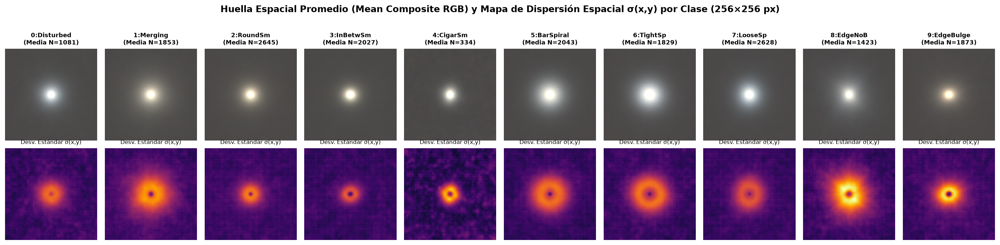

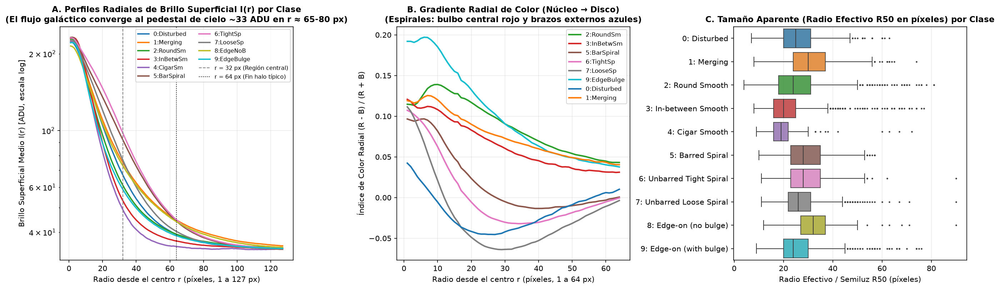

In [6]:
# 1. Huella espacial promedio (Mean Stack) y mapa de desviación estándar σ(x,y) por clase
fig, axes = plt.subplots(2, 10, figsize=(20, 4.8))
for c_id in range(10):
    m_img = np.clip(mean_img_by_class[c_id] / 180.0, 0, 1) ** 0.75
    s_img = np.clip(std_img_by_class[c_id].mean(axis=-1), 0, 65)
    axes[0, c_id].imshow(m_img)
    axes[0, c_id].set_title(f"{SHORT_NAMES[c_id]}\n(Media N={counts[c_id]})", fontsize=8.5, fontweight="bold")
    axes[0, c_id].axis("off")

    axes[1, c_id].imshow(s_img, cmap="inferno", vmin=10, vmax=60)
    axes[1, c_id].set_title("Desv. Estándar σ(x,y)", fontsize=8)
    axes[1, c_id].axis("off")

fig.suptitle("Huella Espacial Promedio (Mean Composite RGB) y Mapa de Dispersión Espacial σ(x,y) por Clase (256×256 px)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# 2. Perfiles radiales de brillo superficial I(r), gradiente radial de color y radio de semiluz R50
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
r_px = np.arange(1, 128)

ax = axes[0]
for c_id in range(10):
    prof_luma = radial_prof_by_class[c_id, 1:].mean(axis=-1)
    ax.plot(r_px, prof_luma, color=PALETTE[c_id], lw=1.8, label=SHORT_NAMES[c_id])
ax.axvline(32, color="gray", linestyle="--", lw=1, label="r = 32 px (Región central)")
ax.axvline(64, color="black", linestyle=":", lw=1, label="r = 64 px (Fin halo típico)")
ax.set_yscale("log")
ax.set_xlabel("Radio desde el centro r (píxeles, 1 a 127 px)")
ax.set_ylabel("Brillo Superficial Medio I(r) [ADU, escala log]")
ax.set_title("A. Perfiles Radiales de Brillo Superficial I(r) por Clase\n(El flujo galáctico converge al pedestal de cielo ~33 ADU en r ≈ 65-80 px)", fontweight="bold")
ax.legend(fontsize=7.5, ncol=2)

ax = axes[1]
for c_id in [2, 3, 5, 6, 7, 9, 0, 1]:
    R_r = radial_prof_by_class[c_id, 1:65, 0]
    B_r = radial_prof_by_class[c_id, 1:65, 2]
    col_r = (R_r - B_r) / (R_r + B_r + 1.0)
    ax.plot(np.arange(1, 65), col_r, color=PALETTE[c_id], lw=2.0, label=SHORT_NAMES[c_id])
ax.set_xlabel("Radio desde el centro r (píxeles, 1 a 64 px)")
ax.set_ylabel("Índice de Color Radial (R - B) / (R + B)")
ax.set_title("B. Gradiente Radial de Color (Núcleo → Disco)\n(Espirales: bulbo central rojo y brazos externos azules)", fontweight="bold")
ax.legend(fontsize=8)

ax = axes[2]
sns.boxplot(
    data=df, x="r50_px", y="class_name", hue="class_name",
    order=[CLASS_NAMES[i] for i in range(10)], palette=PALETTE, legend=False,
    ax=ax, fliersize=1.2, boxprops=dict(alpha=0.85)
)
ax.set_xlabel("Radio Efectivo / Semiluz R50 (píxeles)")
ax.set_ylabel("")
ax.set_title("C. Tamaño Aparente (Radio Efectivo R50 en píxeles) por Clase", fontweight="bold")

plt.tight_layout()
plt.show()


## 7. Colorimetría Astronómica: Secuencia Roja vs Nube Azul, Efecto $K$-Correction y Gradiente Radial

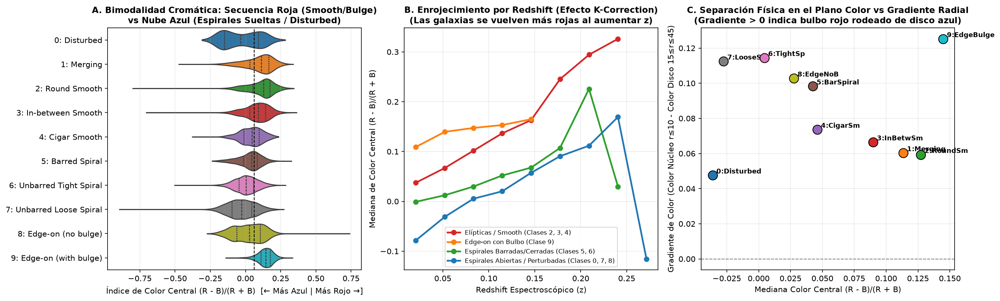

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel A: Distribución del índice de color central (R-B)/(R+B)
ax = axes[0]
sns.violinplot(
    data=df, x="color_RB_center", y="class_name", hue="class_name",
    order=[CLASS_NAMES[i] for i in range(10)], palette=PALETTE, legend=False,
    ax=ax, cut=0, inner="quartile", density_norm="width"
)
ax.axvline(df["color_RB_center"].median(), color="black", linestyle="--", lw=1)
ax.set_xlabel("Índice de Color Central (R - B)/(R + B)  [← Más Azul | Más Rojo →]")
ax.set_ylabel("")
ax.set_title("A. Bimodalidad Cromática: Secuencia Roja (Smooth/Bulge)\nvs Nube Azul (Espirales Sueltas / Disturbed)", fontweight="bold")

# Panel B: Enrojecimiento fotométrico con el redshift (K-correction)
ax = axes[1]
df_z_valid = df[df["redshift"].between(0.005, 0.35)].copy()
df_z_valid["z_bin"] = pd.cut(df_z_valid["redshift"], bins=np.linspace(0.005, 0.35, 12))
z_centers = [b.mid for b in df_z_valid["z_bin"].cat.categories]
for grp_name, cls_list, col_line in [
    ("Elípticas / Smooth (Clases 2, 3, 4)", [2, 3, 4], "#d62728"),
    ("Edge-on con Bulbo (Clase 9)", [9], "#ff7f0e"),
    ("Espirales Barradas/Cerradas (Clases 5, 6)", [5, 6], "#2ca02c"),
    ("Espirales Abiertas / Perturbadas (Clases 0, 7, 8)", [0, 7, 8], "#1f77b4"),
]:
    sub_g = df_z_valid[df_z_valid["ans"].isin(cls_list)]
    med_c = sub_g.groupby("z_bin", observed=False)["color_RB_center"].median()
    ax.plot(z_centers, med_c.values, "-o", color=col_line, lw=2.2, label=grp_name)
ax.set_xlabel("Redshift Espectroscópico (z)")
ax.set_ylabel("Mediana de Color Central (R - B)/(R + B)")
ax.set_title("B. Enrojecimiento por Redshift (Efecto K-Correction)\n(Las galaxias se vuelven más rojas al aumentar z)", fontweight="bold")
ax.legend(fontsize=8)

# Panel C: Plano Color Central vs Gradiente Radial Núcleo-Disco
ax = axes[2]
grp_col = df.groupby("ans")[["color_RB_center", "color_grad_RB", "corr_RB"]].median()
for c_id in range(10):
    ax.scatter(
        grp_col.loc[c_id, "color_RB_center"],
        grp_col.loc[c_id, "color_grad_RB"],
        color=PALETTE[c_id], s=140, edgecolor="black", zorder=5, label=SHORT_NAMES[c_id]
    )
    ax.text(
        grp_col.loc[c_id, "color_RB_center"] + 0.003,
        grp_col.loc[c_id, "color_grad_RB"] + 0.001,
        SHORT_NAMES[c_id], fontsize=8.5, fontweight="bold"
    )
ax.axhline(0, color="gray", linestyle="--", lw=1)
ax.set_xlabel("Mediana Color Central (R - B)/(R + B)")
ax.set_ylabel("Gradiente de Color (Color Núcleo r≤10 - Color Disco 15≤r≤45)")
ax.set_title("C. Separación Física en el Plano Color vs Gradiente Radial\n(Gradiente > 0 indica bulbo rojo rodeado de disco azul)", fontweight="bold")

plt.tight_layout()
plt.show()


## 8. Descriptores Morfológicos Astrofísicos (CAS, Gini–$M_{20}$, Elipticidad, Isotropía $\text{SO}(2)$) y Espectro FFT 2D

=== TABLA DE MEDIANAS DE DESCRIPTORES POR CLASE MORFOLÓGICA ===
                          center_luma   snr_peak  color_RB_center  color_grad_RB  r50_px  concentration_C  asymmetry_180  clumpiness_S    gini     m20  ellipticity  shannon_entropy  redshift
class_name                                                                                                                                                                                    
0: Disturbed               104.390404  15.313700          -0.0362         0.0476    25.0           2.6144         0.2246        0.1288  0.5244 -1.6544       0.1739           3.9839    0.0647
1: Merging                 108.876900  16.139900           0.1134         0.0603    30.0           2.6649         0.3508        0.1035  0.5154 -1.2855       0.2072           4.0825    0.0907
2: Round Smooth             96.086800  15.617900           0.1272         0.0594    24.0           2.7908         0.2188        0.1597  0.5525 -1.7630       0.0712         

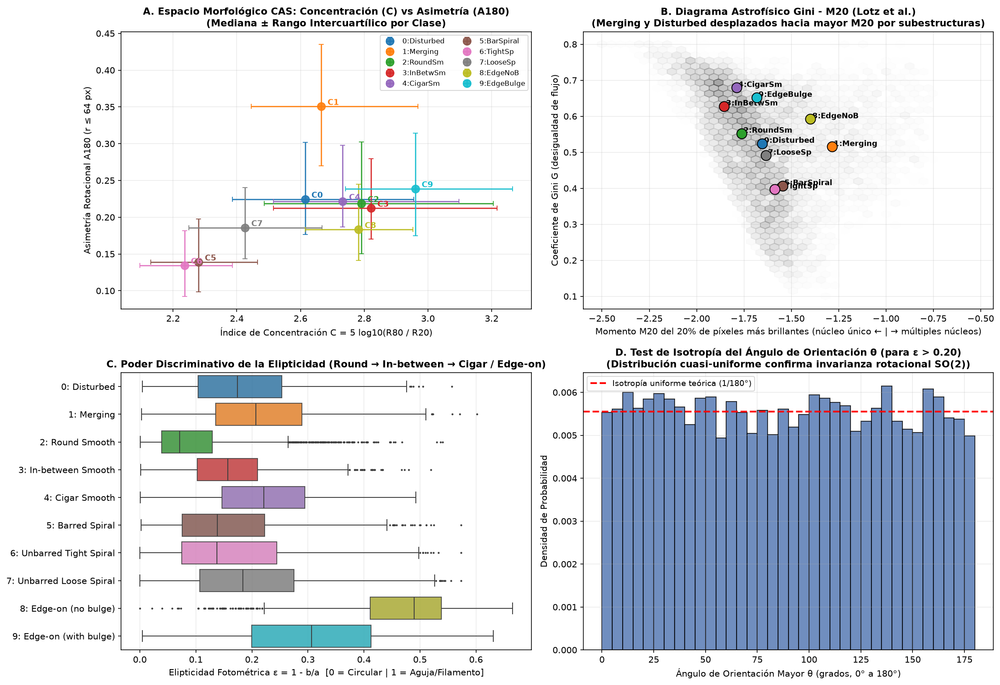

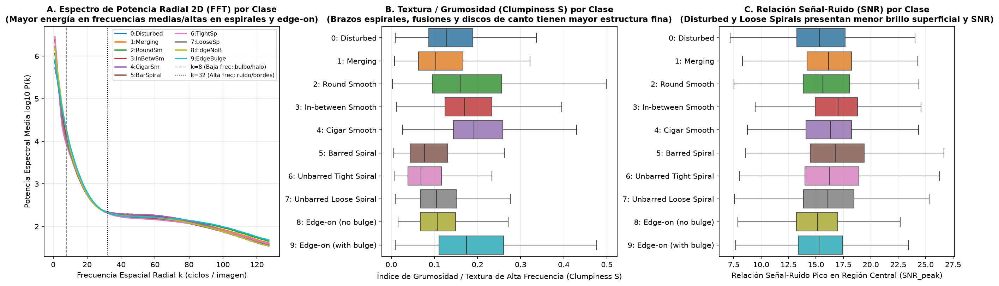

In [8]:
cols_med = [
    "center_luma", "snr_peak", "color_RB_center", "color_grad_RB",
    "r50_px", "concentration_C", "asymmetry_180", "clumpiness_S",
    "gini", "m20", "ellipticity", "shannon_entropy", "redshift"
]
print("=== TABLA DE MEDIANAS DE DESCRIPTORES POR CLASE MORFOLÓGICA ===")
print(df.groupby("class_name")[cols_med].median().round(4).to_string())

# Figura 7: CAS, Gini-M20, Elipticidad e Isotropía del ángulo de orientación
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

ax = axes[0, 0]
for c_id in range(10):
    sub_c = df[df["ans"] == c_id]
    med_C, med_A = sub_c["concentration_C"].median(), sub_c["asymmetry_180"].median()
    q25_C, q75_C = np.percentile(sub_c["concentration_C"], [25, 75])
    q25_A, q75_A = np.percentile(sub_c["asymmetry_180"], [25, 75])
    ax.errorbar(
        med_C, med_A,
        xerr=[[med_C - q25_C], [q75_C - med_C]],
        yerr=[[med_A - q25_A], [q75_A - med_A]],
        fmt="o", color=PALETTE[c_id], markersize=9, elinewidth=1.5, capsize=3, alpha=0.9, label=SHORT_NAMES[c_id]
    )
    ax.text(med_C + 0.02, med_A + 0.002, f"C{c_id}", fontsize=9, fontweight="bold", color=PALETTE[c_id])
ax.set_xlabel("Índice de Concentración C = 5 log10(R80 / R20)")
ax.set_ylabel("Asimetría Rotacional A180 (r ≤ 64 px)")
ax.set_title("A. Espacio Morfológico CAS: Concentración (C) vs Asimetría (A180)\n(Mediana ± Rango Intercuartílico por Clase)", fontweight="bold")
ax.legend(fontsize=8, ncol=2)

ax = axes[0, 1]
for c_id in range(10):
    sub_c = df[df["ans"] == c_id]
    med_m20, med_g = sub_c["m20"].median(), sub_c["gini"].median()
    ax.scatter(med_m20, med_g, color=PALETTE[c_id], s=130, edgecolor="black", zorder=5)
    ax.text(med_m20 + 0.01, med_g + 0.002, SHORT_NAMES[c_id], fontsize=8.5, fontweight="bold")
ax.hexbin(df["m20"].clip(-2.5, -0.5), df["gini"].clip(0.1, 0.8), gridsize=40, cmap="Greys", mincnt=5, alpha=0.35)
ax.set_xlabel("Momento M20 del 20% de píxeles más brillantes (núcleo único ← | → múltiples núcleos)")
ax.set_ylabel("Coeficiente de Gini G (desigualdad de flujo)")
ax.set_title("B. Diagrama Astrofísico Gini - M20 (Lotz et al.)\n(Merging y Disturbed desplazados hacia mayor M20 por subestructuras)", fontweight="bold")

ax = axes[1, 0]
sns.boxplot(
    data=df, x="ellipticity", y="class_name", hue="class_name",
    order=[CLASS_NAMES[i] for i in range(10)], palette=PALETTE, legend=False,
    ax=ax, fliersize=1.2, boxprops=dict(alpha=0.85)
)
ax.set_xlabel("Elipticidad Fotométrica ε = 1 - b/a  [0 = Circular | 1 = Aguja/Filamento]")
ax.set_ylabel("")
ax.set_title("C. Poder Discriminativo de la Elipticidad (Round → In-between → Cigar / Edge-on)", fontweight="bold")

ax = axes[1, 1]
df_elong = df[df["ellipticity"] > 0.20]
ax.hist(df_elong["orientation_deg"], bins=36, range=(0, 180), color="#4c72b0", edgecolor="black", alpha=0.8, density=True)
ax.axhline(1.0 / 180.0, color="red", linestyle="--", lw=2, label="Isotropía uniforme teórica (1/180°)")
ax.set_xlabel("Ángulo de Orientación Mayor θ (grados, 0° a 180°)")
ax.set_ylabel("Densidad de Probabilidad")
ax.set_title("D. Test de Isotropía del Ángulo de Orientación θ (para ε > 0.20)\n(Distribución cuasi-uniforme confirma invarianza rotacional SO(2))", fontweight="bold")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Figura 8: Espectro de Potencia Radial 2D (FFT), Grumosidad (Clumpiness S) y SNR
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
k_freq = np.arange(1, 128)

ax = axes[0]
for c_id in range(10):
    ax.plot(k_freq, fft_radial_by_class[c_id, 1:], color=PALETTE[c_id], lw=1.7, label=SHORT_NAMES[c_id])
ax.axvline(8, color="gray", linestyle="--", lw=1, label="k=8 (Baja frec: bulbo/halo)")
ax.axvline(32, color="black", linestyle=":", lw=1, label="k=32 (Alta frec: ruido/bordes)")
ax.set_xlabel("Frecuencia Espacial Radial k (ciclos / imagen)")
ax.set_ylabel("Potencia Espectral Media log10 P(k)")
ax.set_title("A. Espectro de Potencia Radial 2D (FFT) por Clase\n(Mayor energía en frecuencias medias/altas en espirales y edge-on)", fontweight="bold")
ax.legend(fontsize=7.5, ncol=2)

ax = axes[1]
sns.boxplot(
    data=df, x="clumpiness_S", y="class_name", hue="class_name",
    order=[CLASS_NAMES[i] for i in range(10)], palette=PALETTE, legend=False,
    ax=ax, showfliers=False, boxprops=dict(alpha=0.85)
)
ax.set_xlabel("Índice de Grumosidad / Textura de Alta Frecuencia (Clumpiness S)")
ax.set_ylabel("")
ax.set_title("B. Textura / Grumosidad (Clumpiness S) por Clase\n(Brazos espirales, fusiones y discos de canto tienen mayor estructura fina)", fontweight="bold")

ax = axes[2]
sns.boxplot(
    data=df, x="snr_peak", y="class_name", hue="class_name",
    order=[CLASS_NAMES[i] for i in range(10)], palette=PALETTE, legend=False,
    ax=ax, showfliers=False, boxprops=dict(alpha=0.85)
)
ax.set_xlabel("Relación Señal-Ruido Pico en Región Central (SNR_peak)")
ax.set_ylabel("")
ax.set_title("C. Relación Señal-Ruido (SNR) por Clase\n(Disturbed y Loose Spirals presentan menor brillo superficial y SNR)", fontweight="bold")

plt.tight_layout()
plt.show()


## 9. Auditoría de Calidad: Imágenes Corruptas (`[33,33,33]`), Duplicados Exactos con Etiquetas Contradictorias y Artefactos CCD

=== 1. IMÁGENES CORRUPTAS / VACÍAS (std_luma < 1.0) ===
  idx  ans               class_name  mean_luma  std_luma        ra       dec  redshift
11492    6 6: Unbarred Tight Spiral       32.0       0.0 54.117802  1.128996  0.068250
12659    7 7: Unbarred Loose Spiral       32.0       0.0 53.543953  1.103353  0.047719
15422    8    8: Edge-on (no bulge)       32.0       0.0 57.326393 -0.691512  0.047368

=== 2. GRUPOS DE DUPLICADOS EXACTOS MD5 (60 grupos, 121 imágenes; 100% con etiquetas contradictorias) ===
  19x : 0: Disturbed  <-->  7: Unbarred Loose Spiral
   8x : 1: Merging  <-->  7: Unbarred Loose Spiral
   6x : 0: Disturbed  <-->  3: In-between Smooth
   5x : 2: Round Smooth  <-->  6: Unbarred Tight Spiral
   4x : 0: Disturbed  <-->  2: Round Smooth
   4x : 7: Unbarred Loose Spiral  <-->  9: Edge-on (with bulge)
   2x : 5: Barred Spiral  <-->  9: Edge-on (with bulge)
   2x : 1: Merging  <-->  5: Barred Spiral
   2x : 6: Unbarred Tight Spiral  <-->  9: Edge-on (with bulge)
   1x : 6

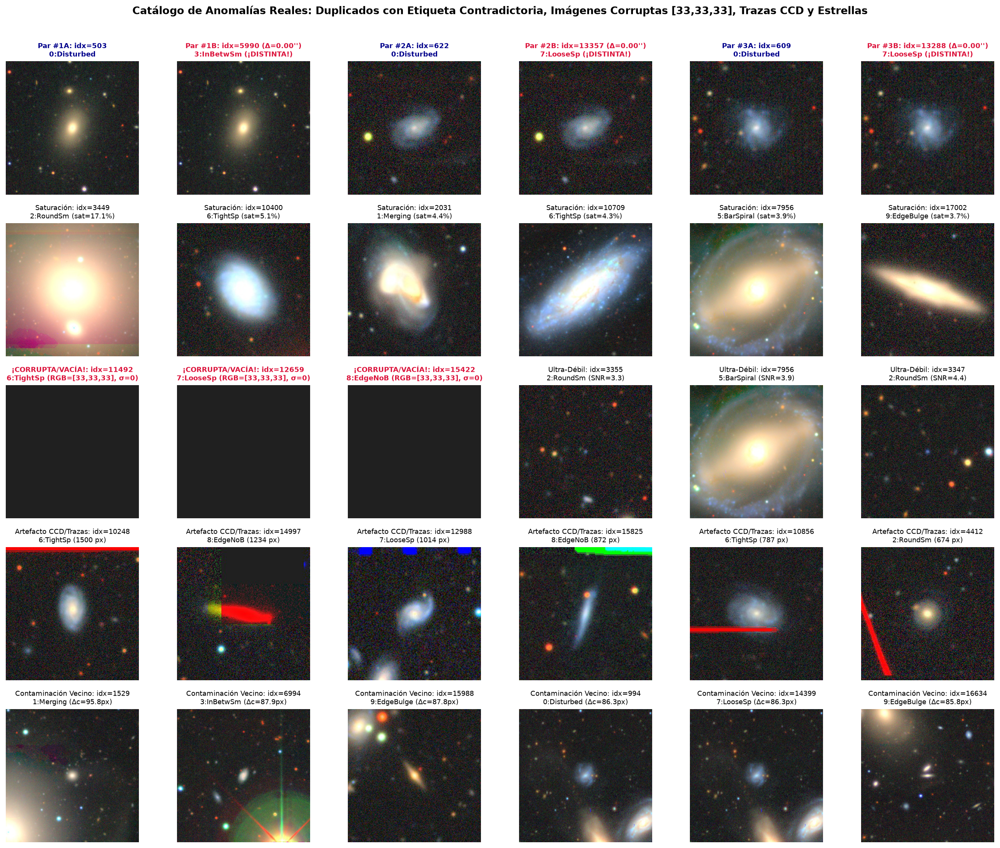

In [9]:
print("=== 1. IMÁGENES CORRUPTAS / VACÍAS (std_luma < 1.0) ===")
print(df[df["std_luma"] < 1.0][["idx", "ans", "class_name", "mean_luma", "std_luma", "ra", "dec", "redshift"]].to_string(index=False))

dup_md5 = df[df.duplicated("md5", keep=False)].sort_values("md5")
pair_counts = Counter()
for md5_val, grp in dup_md5.groupby("md5"):
    pair_counts[tuple(sorted(grp["class_name"].tolist()))] += 1

print(f"\n=== 2. GRUPOS DE DUPLICADOS EXACTOS MD5 ({dup_md5['md5'].nunique()} grupos, {len(dup_md5)} imágenes; 100% con etiquetas contradictorias) ===")
for k, v in pair_counts.most_common():
    print(f"  {v:2d}x : {'  <-->  '.join(k)}")

# Galería visual de anomalías detectadas
fig, axes = plt.subplots(5, 6, figsize=(18, 14.5))

# Fila 0: Pares de coordenadas celestes idénticas (< 8 arcsec) con etiquetas contradictorias
sky_pairs = df[df["nearest_sky_arcsec"] < 8.0].sort_values("nearest_sky_arcsec")
seen_pairs, used_idx = [], set()
for _, row in sky_pairs.iterrows():
    i1, i2 = int(row["idx"]), int(row["nearest_sky_idx"])
    if i1 not in used_idx and i2 not in used_idx:
        seen_pairs.append((i1, i2, row["nearest_sky_arcsec"], int(row["ans"]), int(df.loc[i2, "ans"])))
        used_idx.update([i1, i2])
    if len(seen_pairs) == 3:
        break

for p_i, (i1, i2, sep, c1, c2) in enumerate(seen_pairs):
    axes[0, 2*p_i].imshow(get_cached_img(i1))
    axes[0, 2*p_i].set_title(f"Par #{p_i+1}A: idx={i1}\n{SHORT_NAMES[c1]}", fontsize=8.5, fontweight="bold", color="darkblue")
    axes[0, 2*p_i+1].imshow(get_cached_img(i2))
    col_t = "darkgreen" if c1 == c2 else "crimson"
    axes[0, 2*p_i+1].set_title(f"Par #{p_i+1}B: idx={i2} (Δ={sep:.2f}'')\n{SHORT_NAMES[c2]} ({'Misma' if c1==c2 else '¡DISTINTA!'})", fontsize=8.5, fontweight="bold", color=col_t)

# Fila 1: Saturación extrema / contaminación por estrellas brillantes
sat_top = df[df["idx"].isin(keep_idx_arr)].nlargest(6, "sat_frac_all")
for j, (_, row) in enumerate(sat_top.iterrows()):
    axes[1, j].imshow(get_cached_img(int(row["idx"])))
    axes[1, j].set_title(f"Saturación: idx={int(row['idx'])}\n{SHORT_NAMES[int(row['ans'])]} (sat={row['sat_frac_all']*100:.1f}%)", fontsize=8.5)

# Fila 2: Las 3 imágenes vacías/corruptas [33,33,33] + 3 galaxias ultra-débiles reales
blank_rows = df[df["idx"].isin(keep_idx_arr) & (df["std_luma"] < 1.0)]
for j, (_, row) in enumerate(blank_rows.iterrows()):
    axes[2, j].imshow(get_cached_img(int(row["idx"])))
    axes[2, j].set_title(f"¡CORRUPTA/VACÍA!: idx={int(row['idx'])}\n{SHORT_NAMES[int(row['ans'])]} (RGB=[33,33,33], σ=0)", fontsize=8.5, fontweight="bold", color="crimson")

faint_rows = df[df["idx"].isin(keep_idx_arr) & (df["std_luma"] > 1.0)].nsmallest(3, "snr_peak")
for j, (_, row) in enumerate(faint_rows.iterrows()):
    axes[2, 3 + j].imshow(get_cached_img(int(row["idx"])))
    axes[2, 3 + j].set_title(f"Ultra-Débil: idx={int(row['idx'])}\n{SHORT_NAMES[int(row['ans'])]} (SNR={row['snr_peak']:.1f})", fontsize=8.5)

# Fila 3: Artefactos monocromáticos CCD / trazas de satélite / bordes de placa
anom_top = df[df["idx"].isin(keep_idx_arr)].nlargest(6, "single_band_anom_px")
for j, (_, row) in enumerate(anom_top.iterrows()):
    axes[3, j].imshow(get_cached_img(int(row["idx"])))
    axes[3, j].set_title(f"Artefacto CCD/Trazas: idx={int(row['idx'])}\n{SHORT_NAMES[int(row['ans'])]} ({int(row['single_band_anom_px'])} px)", fontsize=8.5)

# Fila 4: Contaminación severa por vecinos brillantes (desplazamiento del centroide)
off_top = df[df["idx"].isin(keep_idx_arr)].nlargest(6, "centroid_offset_full_px")
for j, (_, row) in enumerate(off_top.iterrows()):
    axes[4, j].imshow(get_cached_img(int(row["idx"])))
    axes[4, j].set_title(f"Contaminación Vecino: idx={int(row['idx'])}\n{SHORT_NAMES[int(row['ans'])]} (Δc={row['centroid_offset_full_px']:.1f}px)", fontsize=8.5)

for r in range(5):
    for c in range(6):
        axes[r, c].axis("off")

fig.suptitle("Catálogo de Anomalías Reales: Duplicados con Etiqueta Contradictoria, Imágenes Corruptas [33,33,33], Trazas CCD y Estrellas", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


## 10. Análisis Multivariante: Correlación de Descriptores, Proyección PCA y Matriz de Separabilidad entre Clases

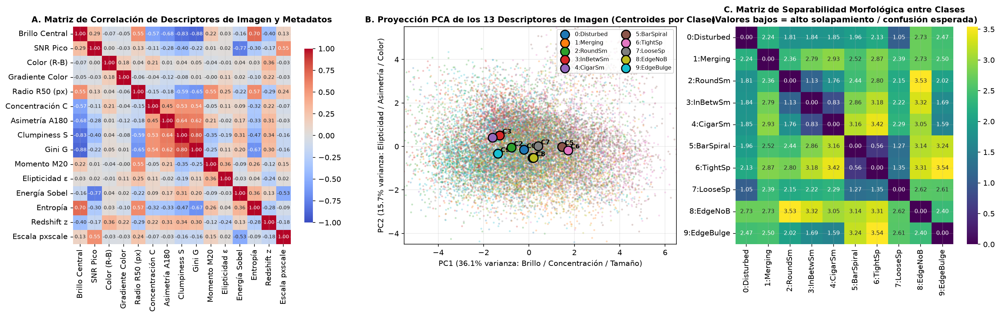

In [10]:
feat_cols = [
    "center_luma", "snr_peak", "color_RB_center", "color_grad_RB",
    "r50_px", "concentration_C", "asymmetry_180", "clumpiness_S",
    "gini", "m20", "ellipticity", "sobel_energy", "shannon_entropy",
    "redshift", "pxscale"
]
feat_labels = [
    "Brillo Central", "SNR Pico", "Color (R-B)", "Gradiente Color",
    "Radio R50 (px)", "Concentración C", "Asimetría A180", "Clumpiness S",
    "Gini G", "Momento M20", "Elipticidad ε", "Energía Sobel", "Entropía",
    "Redshift z", "Escala pxscale"
]

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

# Panel A: Matriz de correlación
ax = axes[0]
corr_mat = df[feat_cols].corr()
sns.heatmap(
    corr_mat, xticklabels=feat_labels, yticklabels=feat_labels,
    cmap="coolwarm", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
    annot_kws={"size": 6.5}, cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("A. Matriz de Correlación de Descriptores de Imagen y Metadatos", fontweight="bold")

# Panel B: Proyección PCA (SVD) sobre los 13 descriptores morfológicos/fotométricos
ax = axes[1]
X_df = df[feat_cols[:-2]].fillna(df[feat_cols[:-2]].median())
X = np.clip((X_df.values - X_df.values.mean(axis=0)) / (X_df.values.std(axis=0) + 1e-8), -5, 5)
U, S, Vt = np.linalg.svd(X, full_matrices=False)
Z_pca = U[:, :2] * S[:2]
var_exp = (S[:2] ** 2) / (S ** 2).sum() * 100

for c_id in range(10):
    m = (df["ans"].values == c_id)
    ax.scatter(Z_pca[m, 0], Z_pca[m, 1], color=PALETTE[c_id], s=3, alpha=0.18)
    cx_p, cy_p = np.median(Z_pca[m, 0]), np.median(Z_pca[m, 1])
    ax.scatter(cx_p, cy_p, color=PALETTE[c_id], s=140, edgecolor="black", linewidth=1.5, zorder=10, label=SHORT_NAMES[c_id])
    ax.text(cx_p + 0.12, cy_p + 0.08, f"C{c_id}", fontsize=8.5, fontweight="bold")
ax.set_xlim(-5.5, 6.5)
ax.set_ylim(-4.5, 5.5)
ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% varianza: Brillo / Concentración / Tamaño)")
ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% varianza: Elipticidad / Asimetría / Color)")
ax.set_title("B. Proyección PCA de los 13 Descriptores de Imagen (Centroides por Clase)", fontweight="bold")
ax.legend(fontsize=7.5, ncol=2, loc="upper right")

# Panel C: Matriz de distancias euclídeas entre centroides de clase
ax = axes[2]
centroids = np.array([np.median(X[df["ans"].values == c_id], axis=0) for c_id in range(10)])
dist_mat = np.sqrt(((centroids[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=-1))
sns.heatmap(
    dist_mat, xticklabels=SHORT_NAMES, yticklabels=SHORT_NAMES,
    cmap="viridis", annot=True, fmt=".2f", annot_kws={"size": 7.5}, ax=ax
)
ax.set_title("C. Matriz de Separabilidad Morfológica entre Clases\n(Valores bajos = alto solapamiento / confusión esperada)", fontweight="bold")

plt.tight_layout()
plt.show()


## 11. Función Lista para Limpieza, Deduplicación y Agrupación Celeste (`Sky Group ID`)

In [11]:
def build_clean_galaxy10_index(df, remove_blank=True, deduplicate_md5="drop_both"):
    """
    Filtra las imágenes corruptas (std_luma < 1.0) y gestiona los duplicados exactos MD5
    que presentan etiquetas contradictorias. Asigna además un `sky_group_id` conectando
    vecinos celestes a < 15 arcsec para usar en StratifiedGroupKFold.
    """
    work = df.copy()
    n_init = len(work)

    if remove_blank:
        work = work[work["std_luma"] >= 1.0].copy()
        print(f"Eliminadas {n_init - len(work)} imágenes corruptas/vacías (RGB=[33,33,33]).")

    if deduplicate_md5 == "drop_both":
        before = len(work)
        work = work[~work.duplicated("md5", keep=False)].copy()
        print(f"Eliminadas {before - len(work)} imágenes con hash MD5 duplicado y etiqueta contradictoria.")
    elif deduplicate_md5 == "keep_first":
        before = len(work)
        work = work.drop_duplicates("md5", keep="first").copy()
        print(f"Conservada 1ª instancia de cada MD5 ({before - len(work)} duplicadas descartadas).")

    # Construir componentes conexas de vecinos celestes (< 15 arcsec) para evitar data leakage
    parent = {int(i): int(i) for i in work["idx"]}
    valid_set = set(parent.keys())
    def find(u):
        while parent[u] != u:
            parent[u] = parent[parent[u]]
            u = parent[u]
        return u

    for _, r in work[work["nearest_sky_arcsec"] < 15.0].iterrows():
        u, v = int(r["idx"]), int(r["nearest_sky_idx"])
        if v in valid_set:
            ru, rv = find(u), find(v)
            if ru != rv:
                parent[max(ru, rv)] = min(ru, rv)

    work["sky_group_id"] = [find(int(i)) for i in work["idx"]]
    print(f"Dataset limpio final: {len(work)} imágenes distribuidas en {work['sky_group_id'].nunique()} grupos celestes independientes.")
    return work

df_clean = build_clean_galaxy10_index(df, remove_blank=True, deduplicate_md5="drop_both")


Eliminadas 3 imágenes corruptas/vacías (RGB=[33,33,33]).
Eliminadas 118 imágenes con hash MD5 duplicado y etiqueta contradictoria.
Dataset limpio final: 17615 imágenes distribuidas en 17534 grupos celestes independientes.
